<a href="https://colab.research.google.com/github/titarzra/Tugas-MachineLearning_TitaRizekyRahmadina_202343500097/blob/main/Bab_11_Dimensionality_Reduction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Bagian A — Implementasi Python

### Praktikum 11.1 Persiapan Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

### Praktikum 11.2 Import Dataset

In [2]:
digits = load_digits()
X, y = digits.data, digits.target
print("Dimensi data asli:", X.shape)   # (1797, 64)

Dimensi data asli: (1797, 64)


### Praktikum 11.3 Preprocessing

In [3]:
X_scaled = StandardScaler().fit_transform(X)

### Praktikum 11.4 Training Model (PCA, t-SNE, LDA)

In [4]:
pca = PCA(n_components=0.90)   # pertahankan 90% variance
X_pca = pca.fit_transform(X_scaled)
print("Jumlah komponen untuk 90% variance:", pca.n_components_)

X_tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(X_scaled)

lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X_scaled, y)   # LDA memerlukan label y

Jumlah komponen untuk 90% variance: 31


### Praktikum 11.5 Evaluasi

In [5]:
print("Explained variance ratio (5 komponen pertama):", np.round(pca.explained_variance_ratio_[:5], 3))
print("Total variance dijelaskan:", round(pca.explained_variance_ratio_.sum(), 3))

Explained variance ratio (5 komponen pertama): [0.12  0.096 0.084 0.065 0.049]
Total variance dijelaskan: 0.9


### Praktikum 11.6 Visualisasi

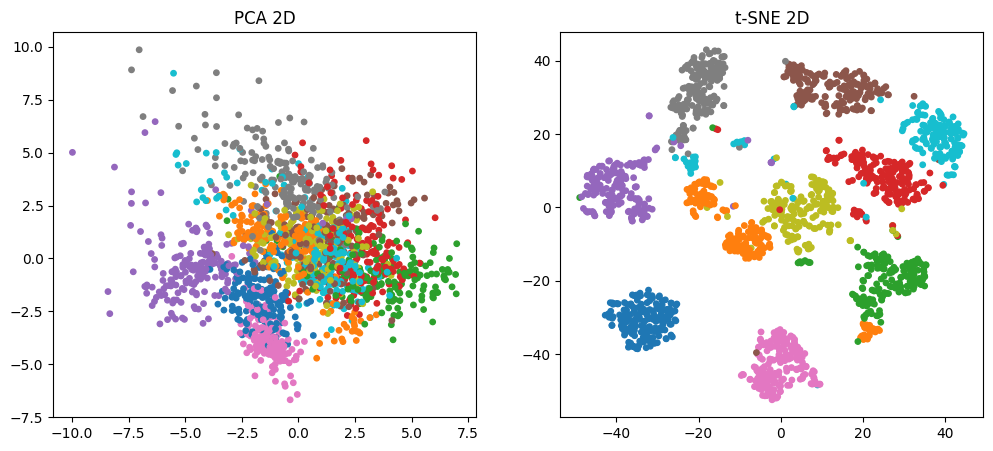

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="tab10", s=15)
axes[0].set_title("PCA 2D")
axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap="tab10", s=15)
axes[1].set_title("t-SNE 2D")
plt.show()

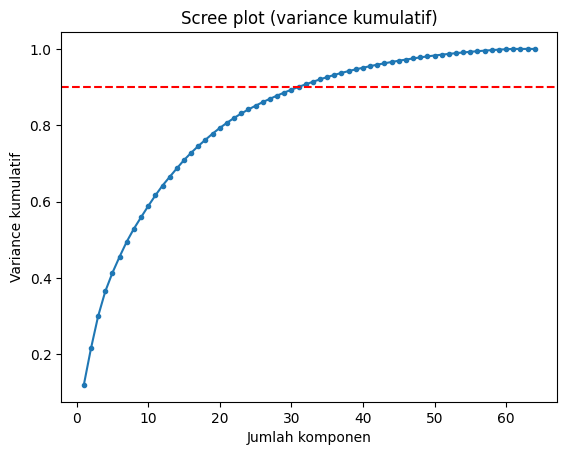

In [7]:
# Scree plot (pelengkap)
pca_full = PCA().fit(X_scaled)
cum = np.cumsum(pca_full.explained_variance_ratio_)
plt.plot(range(1, len(cum) + 1), cum, 'o-', ms=3)
plt.axhline(0.90, ls="--", color="red"); plt.xlabel("Jumlah komponen"); plt.ylabel("Variance kumulatif")
plt.title("Scree plot (variance kumulatif)"); plt.show()

### Praktikum 1 — Kompresi Dimensi dengan PCA (Praktikum 11.7)

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import time

Xtr_raw, Xte_raw, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
sc = StandardScaler().fit(Xtr_raw)                  # scaler hanya dari train
X_train, X_test = sc.transform(Xtr_raw), sc.transform(Xte_raw)

rows = []
for n_comp in [0.80, 0.90, 0.95, None]:
    pca_i = PCA(n_components=n_comp) if n_comp else PCA()
    X_train_p = pca_i.fit_transform(X_train)
    X_test_p = pca_i.transform(X_test)
    t0 = time.perf_counter()
    model = LogisticRegression(max_iter=2000).fit(X_train_p, y_train)
    t_fit = (time.perf_counter() - t0) * 1000
    acc = accuracy_score(y_test, model.predict(X_test_p))
    print(f"n_components={n_comp}: dimensi={X_train_p.shape[1]}, akurasi={acc:.3f}")
    rows.append({"n_components": "semua (tanpa reduksi)" if n_comp is None else n_comp,
                 "dimensi": X_train_p.shape[1], "variance dijelaskan": pca_i.explained_variance_ratio_.sum(),
                 "akurasi test": acc, "waktu latih (ms)": t_fit})
tabel_pca = pd.DataFrame(rows).set_index("n_components")
tabel_pca.round(3)

n_components=0.8: dimensi=21, akurasi=0.950
n_components=0.9: dimensi=31, akurasi=0.964
n_components=0.95: dimensi=40, akurasi=0.961
n_components=None: dimensi=64, akurasi=0.972


,dimensi,variance dijelaskan,akurasi test,waktu latih (ms)
n_components,,,,
0.8,21,0.809,0.950,445.959
0.9,31,0.903,0.964,578.365
0.95,40,0.952,0.961,1236.020
semua (tanpa reduksi),64,1.000,0.972,883.426


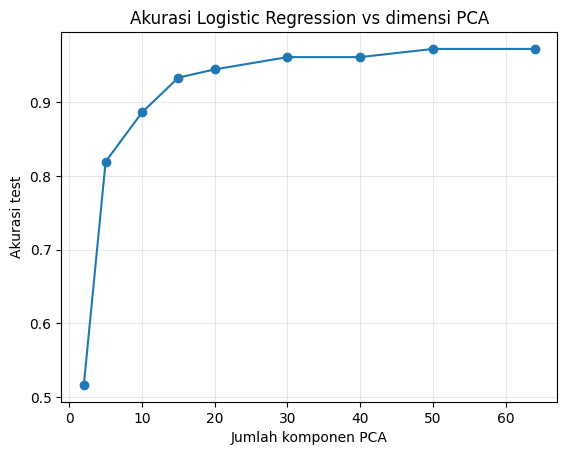

In [9]:
# Kurva akurasi terhadap jumlah komponen (lebih rinci)
komp = [2, 5, 10, 15, 20, 30, 40, 50, 64]
akurasi_komp = []
for k in komp:
    p = PCA(n_components=k).fit(X_train)
    m = LogisticRegression(max_iter=2000).fit(p.transform(X_train), y_train)
    akurasi_komp.append(accuracy_score(y_test, m.predict(p.transform(X_test))))
plt.plot(komp, akurasi_komp, 'o-'); plt.xlabel("Jumlah komponen PCA"); plt.ylabel("Akurasi test")
plt.title("Akurasi Logistic Regression vs dimensi PCA"); plt.grid(alpha=.3); plt.show()

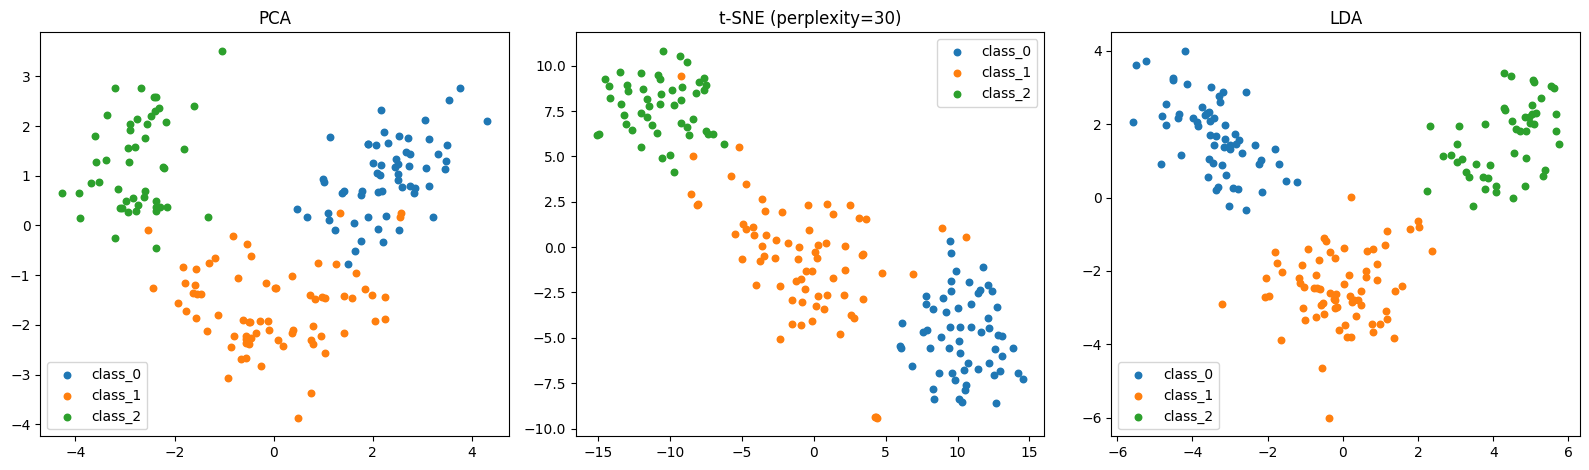

,Silhouette (label asli),Akurasi KNN CV (2D)
Metode,,
PCA,0.526,0.967
t-SNE (perplexity=30),0.552,0.944
LDA,0.663,0.994


In [10]:
from sklearn.datasets import load_wine
from sklearn.metrics import silhouette_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

wine = load_wine()
Xw, yw = wine.data, wine.target
Xw_s = StandardScaler().fit_transform(Xw)

emb = {
    "PCA": PCA(n_components=2).fit_transform(Xw_s),
    "t-SNE (perplexity=30)": TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(Xw_s),
    "LDA": LinearDiscriminantAnalysis(n_components=2).fit_transform(Xw_s, yw),
}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (nama, Z) in zip(axes, emb.items()):
    for k, nm in enumerate(wine.target_names):
        ax.scatter(Z[yw == k, 0], Z[yw == k, 1], s=22, label=nm)
    ax.set_title(nama); ax.legend()
plt.tight_layout(); plt.show()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
baris = []
for nama, Z in emb.items():
    baris.append({"Metode": nama, "Silhouette (label asli)": silhouette_score(Z, yw),
                  "Akurasi KNN CV (2D)": cross_val_score(KNeighborsClassifier(5), Z, yw, cv=skf).mean()})
pd.DataFrame(baris).set_index("Metode").round(3)

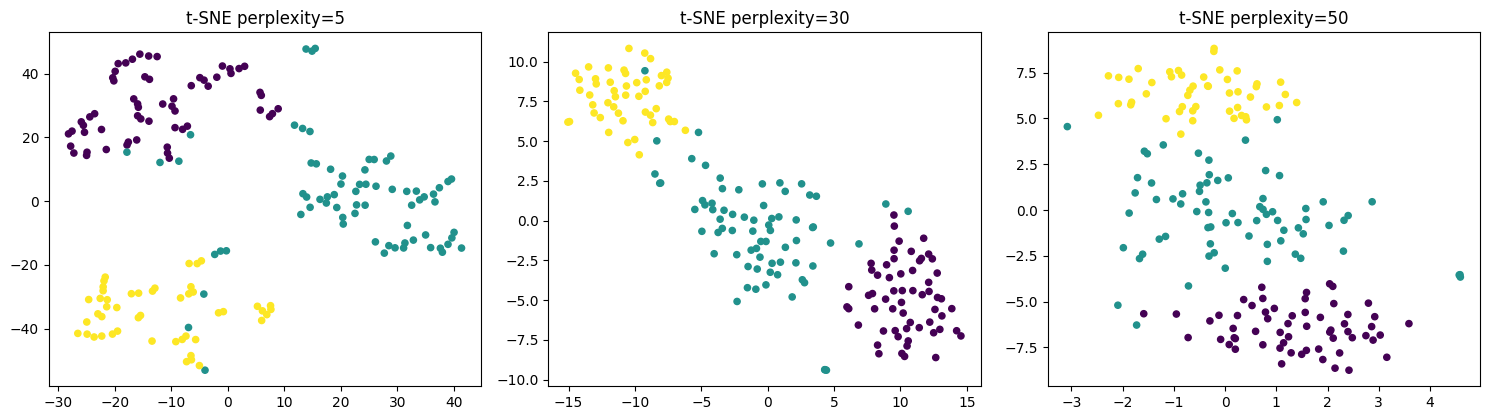

In [11]:
# Pengaruh perplexity pada t-SNE (pelengkap)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, perp in zip(axes, [5, 30, 50]):
    Z = TSNE(n_components=2, perplexity=perp, random_state=42).fit_transform(Xw_s)
    ax.scatter(Z[:, 0], Z[:, 1], c=yw, cmap="viridis", s=20); ax.set_title(f"t-SNE perplexity={perp}")
plt.tight_layout(); plt.show()